# 02 · Pronóstico, intervalos y horizonte

Aquí se decide **cómo pronosticar** y **hasta cuándo confiar** en el pronóstico. Se usan las variables elegidas en el notebook 01.

In [1]:
import warnings
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import coint

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (11, 4.5)

# En local: la carpeta Datos del repositorio.
# En Colab Enterprise: la ruta de los datos de producción, en solo lectura,
# por ejemplo "gs://PROYECTO-PROD-crudos/datos".
ORIGEN = "../Datos"
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

eq = pd.read_csv(f"{ORIGEN}/historico_equipos.csv", parse_dates=["Date"]).set_index("Date").sort_index()
eq.columns = [c.replace("Price_", "") for c in eq.columns]
mensual = eq.resample("MS").mean().dropna()

# Resultado del notebook 01. En producción, el pipeline lo recalcula en cada corrida.
VARIABLES = {"Equipo1": ["X", "Y"], "Equipo2": ["X", "Y", "Z"]}

## Paso 7. Pronóstico de materias primas y error por horizonte

El **backtesting** simula haber pronosticado desde 36 meses distintos y mide cuánto se equivocó cada método a 1, 2 y hasta 12 meses. Siempre se compara contra el **pronóstico ingenuo**, que repite el último valor.

In [2]:
def backtest(serie, pronosticar, horizonte=12, n_origenes=36):
    filas = []
    ultimo_origen = len(serie) - horizonte
    for origen in range(ultimo_origen - n_origenes + 1, ultimo_origen + 1):
        historia, futuro = serie.iloc[:origen], serie.iloc[origen:origen + horizonte]
        pred = pronosticar(historia, horizonte)
        for h in range(horizonte):
            filas.append({"h": h + 1, "ape": abs(futuro.iloc[h] - pred[h]) / futuro.iloc[h] * 100})
    return pd.DataFrame(filas).groupby("h")["ape"].mean()

metodos = {
    "ingenuo": lambda s, h: np.repeat(s.iloc[-1], h),
    "arima": lambda s, h: np.exp(ARIMA(np.log(s.values), order=(1, 1, 0)).fit().forecast(h)),
    "suavizamiento": lambda s, h: np.exp(
        ExponentialSmoothing(np.log(s.values), trend="add", damped_trend=True).fit().forecast(h)),
}
curvas = {(mp, nombre): backtest(mensual[mp], f) for mp in ["X", "Y", "Z"] for nombre, f in metodos.items()}
tabla = pd.DataFrame(curvas).T
tabla.index.names = ["materia_prima", "metodo"]
tabla[[1, 3, 6, 12]].round(1)

h                              1     3     6     12
materia_prima metodo                               
X             ingenuo         9.7  20.7  31.6  33.6
              arima           8.7  21.0  31.1  34.0
              suavizamiento  10.1  21.3  32.4  34.5
Y             ingenuo         5.7  13.7  20.5  32.6
              arima           5.2  13.5  20.5  31.6
              suavizamiento   5.5  13.9  21.7  33.5
Z             ingenuo         5.2  11.8  17.7  24.0
              arima           4.9  11.4  17.5  23.8
              suavizamiento   5.2  12.4  18.3  26.2

Si ningún modelo le gana claramente al ingenuo, se dice y se usa el más simple. Es un hallazgo honesto y común en materias primas, cuyos precios se comportan casi como una caminata aleatoria.

## Paso 8. Pronóstico del costo con intervalos por simulación

La simulación de Montecarlo genera 5,000 escenarios tomando **meses históricos completos** al azar, lo que conserva la correlación entre materias primas. Cada escenario pasa por la regresión del equipo y los percentiles 5 y 95 forman el intervalo del 90 %.

In [3]:
def simular(equipo, variables, H=12, N=5000, semilla=42):
    rng = np.random.default_rng(semilla)
    final = sm.OLS(mensual[equipo], sm.add_constant(mensual[variables])).fit()
    rend = np.log(mensual[variables]).diff().dropna().values
    ultimo = mensual[variables].iloc[-1].values
    idx = rng.integers(0, len(rend), size=(N, H))
    caminos = ultimo * np.exp(np.cumsum(rend[idx], axis=1))
    sim = final.params["const"] + caminos @ final.params[variables].values + rng.choice(final.resid.values, size=(N, H))
    fechas = pd.date_range(mensual.index[-1] + pd.offsets.MonthBegin(), periods=H, freq="MS")
    pron = pd.DataFrame(np.percentile(sim, [5, 50, 95], axis=0).T, index=fechas, columns=["p5", "p50", "p95"])
    pron["ancho_%"] = (pron["p95"] - pron["p5"]) / pron["p50"] * 100
    pron["h"] = range(1, H + 1)
    return pron

pronosticos = {equipo: simular(equipo, v) for equipo, v in VARIABLES.items()}
pd.concat(pronosticos).round(1)

p5    p50     p95  ancho_%   h
Equipo1 2023-09-01  420.5  459.4   511.5     19.8   1
        2023-10-01  405.2  459.5   538.4     29.0   2
        2023-11-01  394.7  459.7   552.1     34.2   3
        2023-12-01  386.1  460.3   566.5     39.2   4
        2024-01-01  376.7  460.3   577.3     43.6   5
        2024-02-01  368.2  459.9   589.5     48.1   6
        2024-03-01  361.6  459.6   603.1     52.5   7
        2024-04-01  356.6  459.3   617.3     56.8   8
        2024-05-01  350.5  460.4   629.0     60.5   9
        2024-06-01  345.5  460.7   636.4     63.1  10
        2024-07-01  338.7  461.9   641.0     65.4  11
        2024-08-01  334.8  460.9   650.0     68.4  12
Equipo2 2023-09-01  861.0  923.2   992.9     14.3   1
        2023-10-01  833.5  926.9  1020.1     20.1   2
        2023-11-01  816.4  926.7  1043.1     24.5   3
        2023-12-01  801.7  927.0  1062.4     28.1   4
        2024-01-01  787.8  925.9  1079.7     31.5   5
        2024-02-01  774.7  925.9  1096.1     34.7   6
        2024-03-01  762.4  926.3  1109.7     37.5   7
        2024-04-01  755.9  926.8  1123.1     39.6   8
        2024-05-01  747.4  926.9  1140.0     42.4   9
        2024-06-01  740.0  927.6  1153.1     44.5  10
        2024-07-01  727.0  928.5  1169.7     47.7  11
        2024-08-01  720.8  928.0  1181.2     49.6  12

## Cómo elegir el horizonte

Se usan dos curvas: el error por horizonte del paso 7 y el ancho del intervalo del paso 8. El ancho tolerable es un **supuesto de negocio** que se define con la gerencia; aquí se prueba con 30 % y 40 % del p50.

In [4]:
def horizonte(pron, ancho_maximo):
    cumple = (pron.sort_values("h")["ancho_%"] <= ancho_maximo).astype(int)
    return max(int(cumple.cummin().sum()), 1)

pd.DataFrame({umbral: {e: horizonte(p, umbral) for e, p in pronosticos.items()} for umbral in (30, 40)}).rename(
    columns=lambda u: f"meses con ancho <= {u} %")

,meses con ancho <= 30 %,meses con ancho <= 40 %
Equipo1,2,4
Equipo2,4,8


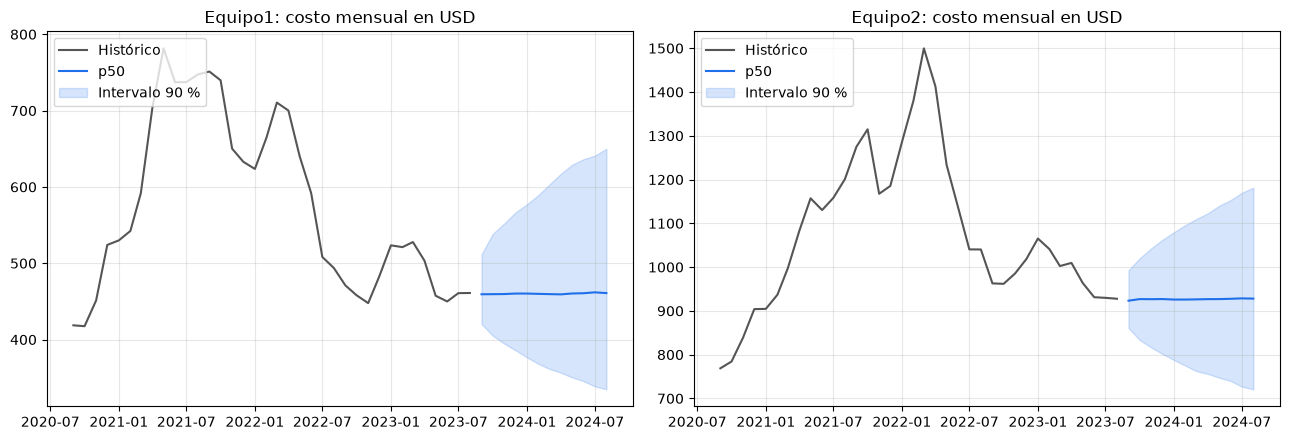

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for eje, (equipo, pron) in zip(ejes, pronosticos.items()):
    historia = mensual[equipo].iloc[-36:]
    eje.plot(historia.index, historia.values, color="#555", label="Histórico")
    eje.plot(pron.index, pron["p50"], color="#1f6feb", label="p50")
    eje.fill_between(pron.index, pron["p5"], pron["p95"], color="#1f6feb", alpha=0.18, label="Intervalo 90 %")
    eje.set_title(f"{equipo}: costo mensual en USD")
    eje.grid(alpha=0.3)
    eje.legend(loc="upper left")
plt.tight_layout()
plt.show()

## Conclusiones del notebook

- **Ningún método le gana con claridad al ingenuo** en las materias primas: el error crece rápido con el horizonte, así que la incertidumbre se comunica con intervalos y no con un solo número.
- **Con un ancho tolerable de 30 %, el horizonte es de 2 meses**, porque el Equipo 1 rebasa ese ancho al tercer mes; el Equipo 2 aguanta hasta el cuarto. Con 40 % el horizonte conjunto sube a 4 meses.
- **Recomendación:** presupuestar con el horizonte corto y re-pronosticar cada mes con datos nuevos. Ese ciclo mensual es justo el pipeline de producción.